# BÀI TẬP LỚN HỌC PHẦN NHẬP MÔN HỌC MÁY (FIT4013)
## ĐỀ TÀI 1: PHÂN LOẠI CẢM XÚC TỪ PHẢN HỒI CỦA SINH VIÊN (STUDENT FEEDBACK SENTIMENT CLASSIFICATION)
**Giảng viên hướng dẫn:** ThS. Lê Thị Thùy Trang  
**Nhóm thực hiện:** Nhóm sinh viên  
**Phạm vi thuật toán đã học:** Multinomial Naive Bayes, Decision Tree (Cây quyết định), K-Nearest Neighbors (K-NN)

---

## MỤC LỤC
1. [Giới thiệu đề tài và mục tiêu bài toán](#1.-Giới-thiệu-đề-tài-và-mục-tiêu-bài-toán)
2. [Khám phá và phân tích dữ liệu (EDA)](#2.-Khám-phá-và-phân-tích-dữ-liệu-(EDA))
3. [Tiền xử lý dữ liệu và phòng chống Data Leakage](#3.-Tiền-xử-lý-dữ-liệu-và-phòng-chống-Data-Leakage)
4. [Mô hình Baseline làm mốc so sánh](#4.-Mô-hình-Baseline-làm-mốc-so-sánh)
5. [So sánh các phương pháp biểu diễn đặc trưng (BoW vs. TF-IDF)](#5.-So-sánh-các-phương-pháp-biểu-diễn-đặc-trưng-(BoW-vs.-TF-IDF))
6. [Huấn luyện mô hình và tinh chỉnh siêu tham số](#6.-Huấn-luyện-mô-hình-và-tinh-chỉnh-siêu-tham-số)
   - 6.1 Multinomial Naive Bayes
   - 6.2 Cây quyết định (Decision Tree)
   - 6.3 K-Nearest Neighbors (K-NN)
7. [Đánh giá đa chiều và so sánh kết quả](#7.-Đánh-giá-đa-chiều-và-so-sánh-kết-quả)
8. [Phân tích lỗi (Error Analysis)](#8.-Phân-tích-lỗi-(Error-Analysis))
9. [Kết luận và hướng phát triển](#9.-Kết-luận-và-hướng-phát-triển)


### 1. Giới thiệu đề tài và mục tiêu bài toán
Bài toán đặt ra là phân loại cảm xúc (Sentiment Analysis) từ các câu nhận xét, phản hồi học thuật của sinh viên thành 3 nhóm: `positive` (tích cực), `neutral` (trung tính), và `negative` (tiêu cực).
Đặc thù bài toán là văn bản ngắn (short text), có sự xuất hiện của yếu tố châm biếm (sarcasm) và sự giao thoa từ vựng lớn giữa các lớp cảm xúc.


In [1]:
import os
import re
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (8, 5)
print("Thư viện được nạp thành công!")


Thư viện được nạp thành công!


### 2. Khám phá và phân tích dữ liệu (EDA)
Đọc bộ dữ liệu `student_feedback_dataset.csv`, kiểm tra kích thước, các trường thông tin, dữ liệu thiếu (missing values) và dữ liệu trùng lặp.


In [2]:
df = pd.read_csv('../data/student_feedback_dataset.csv')
print(f"Kích thước tập dữ liệu: {df.shape[0]} dòng, {df.shape[1]} cột")
display(df.head(5))


Kích thước tập dữ liệu: 1223 dòng, 11 cột


,student_id,department,subject_name,feedback_text,preprocessed_text,sentiment_label,sarcasm_flag,emotion_tag,feedback_type,subject_specific_context,response_required
0,STU0001,CIVIL,Concrete Tech,Attack medical dog technology top several insi...,attack medical dog technology top several insi...,negative,0,anger,Infrastructure,Project-Based,1
1,STU0002,CIVIL,Concrete Tech,Wait worry speak program child past beautiful ...,wait worry speak program child past beautiful ...,positive,0,anger,Infrastructure,Lab-Intensive,0
2,STU0003,BIO,Genetics,Bank those report box your treatment accept in...,bank those report box your treatment accept in...,neutral,0,sadness,Academic,Project-Based,1
3,STU0004,ME,Fluid Mechanics,Can character million listen right amount ask ...,can character million listen right amount ask ...,positive,0,joy,Academic,Theory-Heavy,0
4,STU0005,ME,Fluid Mechanics,Good cost political street dream finish figure.,good cost political street dream finish figure,negative,0,surprise,Academic,Theory-Heavy,1


In [3]:
# Kiểm tra giá trị rỗng và trùng lặp
print("Kiểm tra giá trị thiếu:")
print(df.isnull().sum())
print(f"Số lượng mẫu trùng lặp trong feedback_text: {df['feedback_text'].duplicated().sum()}")


Kiểm tra giá trị thiếu:
student_id                  0
department                  0
subject_name                0
feedback_text               0
preprocessed_text           0
sentiment_label             0
sarcasm_flag                0
emotion_tag                 0
feedback_type               0
subject_specific_context    0
response_required           0
dtype: int64
Số lượng mẫu trùng lặp trong feedback_text: 0


sentiment_label
positive    489
neutral     368
negative    366
Name: count, dtype: int64

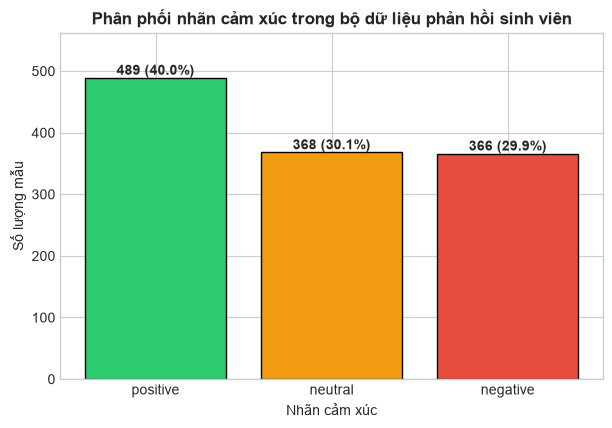

In [4]:
# Phân tích phân phối biến mục tiêu sentiment_label
label_counts = df['sentiment_label'].value_counts()
display(label_counts)

palette = {'positive': '#2ecc71', 'neutral': '#f39c12', 'negative': '#e74c3c'}
plt.figure(figsize=(7, 4.5))
bars = plt.bar(label_counts.index, label_counts.values, color=[palette[c] for c in label_counts.index], edgecolor='black')
for bar in bars:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, h + 5, f"{h} ({h/len(df):.1%})", ha='center', fontweight='bold')
plt.title("Phân phối nhãn cảm xúc trong bộ dữ liệu phản hồi sinh viên", fontweight='bold')
plt.xlabel("Nhãn cảm xúc")
plt.ylabel("Số lượng mẫu")
plt.ylim(0, max(label_counts.values)*1.15)
plt.show()


,count,mean,std,min,25%,50%,75%,max
sentiment_label,,,,,,,,
negative,366.0,11.357923,3.798382,5.0,9.0,11.0,13.75,21.0
neutral,368.0,11.540761,3.983409,4.0,8.0,11.0,15.00,21.0
positive,489.0,11.460123,3.943108,4.0,8.0,11.0,14.00,22.0


C:\Users\Administrator\AppData\Local\Temp\ipykernel_16260\3730305143.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='sentiment_label', y='word_count', palette=palette)


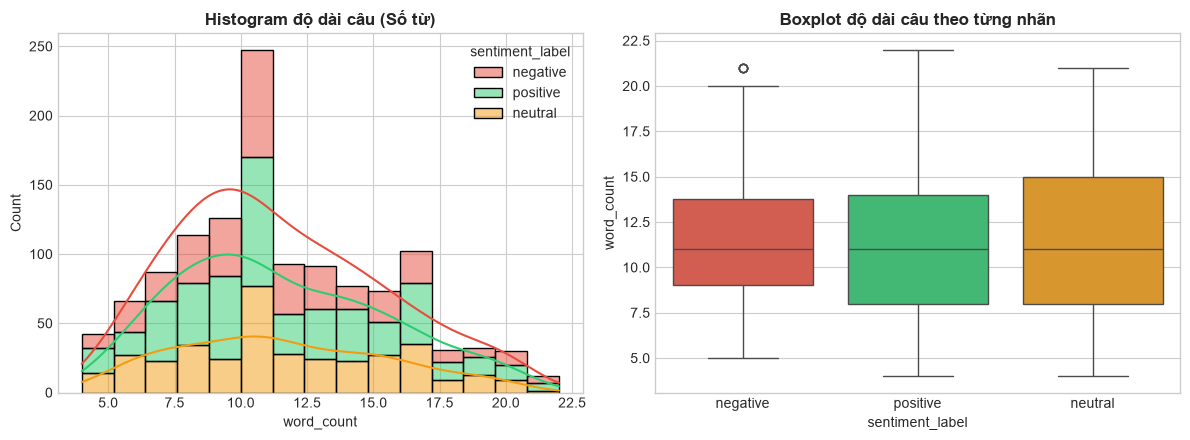

In [5]:
# Phân tích độ dài văn bản (word count)
df['word_count'] = df['feedback_text'].apply(lambda x: len(str(x).split()))
display(df.groupby('sentiment_label')['word_count'].describe())

plt.figure(figsize=(12, 4.5))
plt.subplot(1, 2, 1)
sns.histplot(data=df, x='word_count', hue='sentiment_label', palette=palette, multiple='stack', kde=True, bins=15)
plt.title("Histogram độ dài câu (Số từ)", fontweight='bold')

plt.subplot(1, 2, 2)
sns.boxplot(data=df, x='sentiment_label', y='word_count', palette=palette)
plt.title("Boxplot độ dài câu theo từng nhãn", fontweight='bold')
plt.tight_layout()
plt.show()


sentiment_label,negative,neutral,positive
Không châm biếm (0),29.65,30.12,40.23
Châm biếm (1),31.71,29.88,38.41


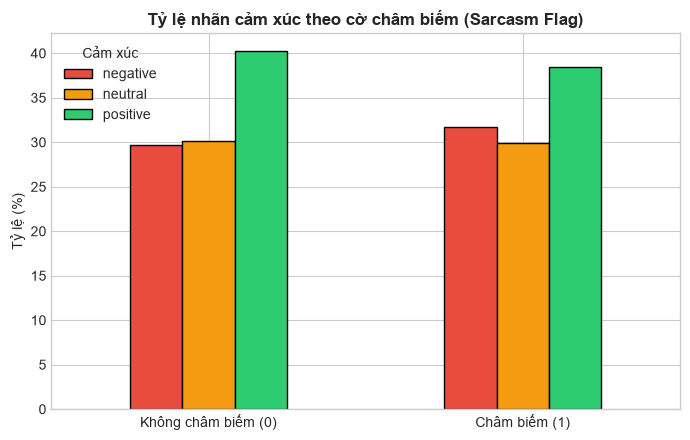

In [6]:
# Phân tích yếu tố châm biếm (Sarcasm Flag)
sarcasm_ct = pd.crosstab(df['sarcasm_flag'], df['sentiment_label'], normalize='index') * 100
sarcasm_ct.index = ['Không châm biếm (0)', 'Châm biếm (1)']
display(sarcasm_ct.round(2))

sarcasm_ct.plot(kind='bar', color=[palette['negative'], palette['neutral'], palette['positive']], edgecolor='black', figsize=(7, 4.5))
plt.title("Tỷ lệ nhãn cảm xúc theo cờ châm biếm (Sarcasm Flag)", fontweight='bold')
plt.ylabel("Tỷ lệ (%)")
plt.xticks(rotation=0)
plt.legend(title="Cảm xúc")
plt.tight_layout()
plt.show()


### 3. Tiền xử lý dữ liệu và phòng chống Data Leakage
Xây dựng hàm làm sạch chuỗi văn bản:
1. Chuyển thành chữ thường (`lowercase`)
2. Loại bỏ URL, thẻ HTML và các ký tự đặc biệt/dấu câu
3. Chuẩn hóa khoảng trắng
4. Lọc stop words có chọn lọc (giữ lại các từ phủ định quan trọng như *not, no, never* để tránh làm mất tín hiệu cảm xúc).

**Quy trình phân chia dữ liệu:**
Tách tập dữ liệu thành Train (80% - 978 mẫu) và Test (20% - 245 mẫu) có phân tầng (`stratify=y`) và cố định `random_state=42`.  
Toàn bộ quá trình học từ vựng (vectorizer.fit) chỉ được thực hiện trên tập Train!


In [7]:
NEGATION_WORDS = {'not', 'no', 'nor', 'never', 'neither', 'hardly', 'scarcely', 'barely'}
CUSTOM_STOP_WORDS = set(ENGLISH_STOP_WORDS) - NEGATION_WORDS

def clean_text(text: str, remove_stopwords: bool = True) -> str:
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    text = re.sub(r'<.*?>', ' ', text)
    text = re.sub(r'[' + re.escape(string.punctuation) + r']', ' ', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    words = text.split()
    if remove_stopwords:
        words = [w for w in words if w not in CUSTOM_STOP_WORDS and len(w) > 1]
    else:
        words = [w for w in words if len(w) > 1]
    return " ".join(words)

# Thử nghiệm hàm clean_text trên một số câu mẫu
for s in df['feedback_text'].head(3):
    print("Gốc: ", s)
    print("Sạch:", clean_text(s))
    print("-" * 50)


Gốc:  Attack medical dog technology top several inside enough.
Sạch: attack medical dog technology inside
--------------------------------------------------
Gốc:  Wait worry speak program child past beautiful write kid radio live blue here staff.
Sạch: wait worry speak program child past beautiful write kid radio live blue staff
--------------------------------------------------
Gốc:  Bank those report box your treatment accept interesting purpose body price nature car bar section final real.
Sạch: bank report box treatment accept interesting purpose body price nature car bar section final real
--------------------------------------------------


In [8]:
# Phân chia dữ liệu Train / Test
X = df['feedback_text']
y = df['sentiment_label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Kích thước tập Huấn luyện (Train): {len(X_train)} mẫu (80%)")
print(f"Kích thước tập Kiểm thử (Test):    {len(X_test)} mẫu (20%)")


Kích thước tập Huấn luyện (Train): 978 mẫu (80%)
Kích thước tập Kiểm thử (Test):    245 mẫu (20%)


### 4. Mô hình Baseline làm mốc so sánh
Sử dụng mô hình dự đoán theo lớp chiếm đa số (`DummyClassifier(strategy='most_frequent')`).  
Mục đích là xác định ngưỡng hiệu năng tối thiểu mà bất kỳ mô hình học máy thực sự nào cũng cần phải vượt qua.


In [9]:
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)

def print_metrics(y_true, y_pred, model_name="Mô hình"):
    acc = accuracy_score(y_true, y_pred)
    mp = precision_score(y_true, y_pred, average='macro', zero_division=0)
    mr = recall_score(y_true, y_pred, average='macro', zero_division=0)
    mf1 = f1_score(y_true, y_pred, average='macro', zero_division=0)
    wf1 = f1_score(y_true, y_pred, average='weighted', zero_division=0)
    print(f"=== ĐÁNH GIÁ: {model_name} ===")
    print(f"Accuracy:          {acc:.4f}")
    print(f"Macro Precision:   {mp:.4f}")
    print(f"Macro Recall:      {mr:.4f}")
    print(f"Macro F1-Score:    {mf1:.4f}")
    print(f"Weighted F1-Score: {wf1:.4f}")
    return {"Model": model_name, "Accuracy": acc, "Macro Precision": mp, "Macro Recall": mr, "Macro F1": mf1, "Weighted F1": wf1}

baseline_res = print_metrics(y_test, y_pred_dummy, "Baseline (Majority Class)")


=== ĐÁNH GIÁ: Baseline (Majority Class) ===
Accuracy:          0.4000
Macro Precision:   0.1333
Macro Recall:      0.3333
Macro F1-Score:    0.1905
Weighted F1-Score: 0.2286


### 5. So sánh các phương pháp biểu diễn đặc trưng (BoW vs. TF-IDF)
Thử nghiệm các cấu hình:
1. `CountVectorizer` (Bag-of-Words unigram)
2. `CountVectorizer` (Bag-of-Words unigram + bigram)
3. `TfidfVectorizer` (TF-IDF unigram)
4. `TfidfVectorizer` (TF-IDF unigram + bigram)
5. `TfidfVectorizer` (min_df=2)
6. `TfidfVectorizer` (Sublinear TF)

Mô hình thử nghiệm chuẩn: Multinomial Naive Bayes ($lpha=1.0$).


,Representation,Vocabulary Size,Accuracy,Macro F1
0,BoW (Unigram),767,0.391837,0.377985
1,BoW (Unigram + Bigram),8601,0.391837,0.340923
2,TF-IDF (Unigram),767,0.400000,0.360470
3,TF-IDF (Unigram + Bigram),8601,0.395918,0.254479
4,TF-IDF (min_df=2),767,0.400000,0.360470
5,TF-IDF (Sublinear TF),767,0.400000,0.360762


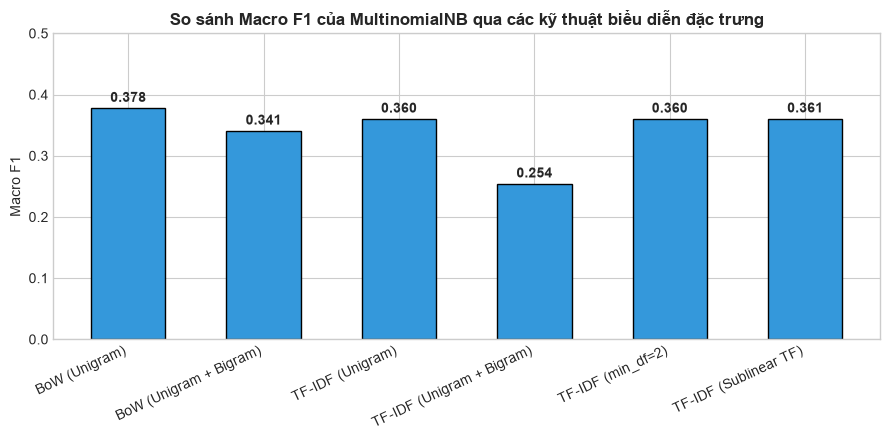

In [10]:
vectorizers = {
    "BoW (Unigram)": CountVectorizer(preprocessor=clean_text, ngram_range=(1, 1)),
    "BoW (Unigram + Bigram)": CountVectorizer(preprocessor=clean_text, ngram_range=(1, 2)),
    "TF-IDF (Unigram)": TfidfVectorizer(preprocessor=clean_text, ngram_range=(1, 1)),
    "TF-IDF (Unigram + Bigram)": TfidfVectorizer(preprocessor=clean_text, ngram_range=(1, 2)),
    "TF-IDF (min_df=2)": TfidfVectorizer(preprocessor=clean_text, ngram_range=(1, 1), min_df=2),
    "TF-IDF (Sublinear TF)": TfidfVectorizer(preprocessor=clean_text, ngram_range=(1, 1), sublinear_tf=True),
}

vec_comparison = []
for name, vec in vectorizers.items():
    X_tr = vec.fit_transform(X_train)
    X_te = vec.transform(X_test)
    
    nb = MultinomialNB(alpha=1.0)
    nb.fit(X_tr, y_train)
    preds = nb.predict(X_te)
    
    acc = accuracy_score(y_test, preds)
    mf1 = f1_score(y_test, preds, average='macro', zero_division=0)
    vec_comparison.append({
        "Representation": name,
        "Vocabulary Size": X_tr.shape[1],
        "Accuracy": acc,
        "Macro F1": mf1
    })

vec_df = pd.DataFrame(vec_comparison)
display(vec_df)

plt.figure(figsize=(9, 4.5))
plt.bar(vec_df['Representation'], vec_df['Macro F1'], color='#3498db', edgecolor='black', width=0.55)
plt.title("So sánh Macro F1 của MultinomialNB qua các kỹ thuật biểu diễn đặc trưng", fontweight='bold')
plt.ylabel("Macro F1")
plt.xticks(rotation=25, ha='right')
plt.ylim(0, 0.5)
for idx, val in enumerate(vec_df['Macro F1']):
    plt.text(idx, val + 0.01, f"{val:.3f}", ha='center', fontweight='bold')
plt.tight_layout()
plt.show()


### 6. Huấn luyện mô hình và tinh chỉnh siêu tham số
Chúng ta sử dụng TF-IDF Unigram làm vectorizer chuẩn hóa (do tính tổng quát hóa tốt và tránh thưa thớt số chiều).
Tiến hành tìm kiếm siêu tham số bằng 5-fold Stratified Cross-Validation (`scoring='f1_macro'`) cho 3 thuật toán:
1. **Multinomial Naive Bayes** (Smoothing parameter $lpha$)
2. **Cây quyết định (Decision Tree)** (`criterion`, `max_depth`, `min_samples_split`)
3. **K-Nearest Neighbors (K-NN)** (`n_neighbors`, `metric`, `weights`)


In [11]:
# Khởi tạo vectorizer chuẩn
tfidf = TfidfVectorizer(preprocessor=clean_text, ngram_range=(1, 1))
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


In [12]:
# 6.1 Multinomial Naive Bayes
param_nb = {'alpha': [0.01, 0.05, 0.1, 0.5, 1.0, 2.0]}
gs_nb = GridSearchCV(MultinomialNB(), param_nb, cv=cv, scoring='f1_macro', n_jobs=-1)
gs_nb.fit(X_train_vec, y_train)
best_nb = gs_nb.best_estimator_
print("MultinomialNB tốt nhất:", gs_nb.best_params_, f"(Best CV Macro F1: {gs_nb.best_score_:.4f})")
y_pred_nb = best_nb.predict(X_test_vec)
nb_res = print_metrics(y_test, y_pred_nb, "Multinomial Naive Bayes")


MultinomialNB tốt nhất: {'alpha': 0.5} (Best CV Macro F1: 0.3311)
=== ĐÁNH GIÁ: Multinomial Naive Bayes ===
Accuracy:          0.3878
Macro Precision:   0.3693
Macro Recall:      0.3648
Macro F1-Score:    0.3570
Weighted F1-Score: 0.3705


In [13]:
# 6.2 Cây quyết định (Decision Tree)
param_dt = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [5, 10, 15, 20, None],
    'min_samples_split': [2, 5, 10]
}
gs_dt = GridSearchCV(DecisionTreeClassifier(random_state=42), param_dt, cv=cv, scoring='f1_macro', n_jobs=-1)
gs_dt.fit(X_train_vec, y_train)
best_dt = gs_dt.best_estimator_
print("Decision Tree tốt nhất:", gs_dt.best_params_, f"(Best CV Macro F1: {gs_dt.best_score_:.4f})")
y_pred_dt = best_dt.predict(X_test_vec)
dt_res = print_metrics(y_test, y_pred_dt, "Decision Tree")


Decision Tree tốt nhất: {'criterion': 'entropy', 'max_depth': None, 'min_samples_split': 2} (Best CV Macro F1: 0.3482)
=== ĐÁNH GIÁ: Decision Tree ===
Accuracy:          0.3429
Macro Precision:   0.3362
Macro Recall:      0.3356
Macro F1-Score:    0.3357
Weighted F1-Score: 0.3428


In [14]:
# 6.3 K-Nearest Neighbors (K-NN)
param_knn = {
    'n_neighbors': [3, 5, 7, 9, 11, 15],
    'metric': ['cosine', 'euclidean'],
    'weights': ['uniform', 'distance']
}
gs_knn = GridSearchCV(KNeighborsClassifier(), param_knn, cv=cv, scoring='f1_macro', n_jobs=-1)
gs_knn.fit(X_train_vec, y_train)
best_knn = gs_knn.best_estimator_
print("KNN tốt nhất:", gs_knn.best_params_, f"(Best CV Macro F1: {gs_knn.best_score_:.4f})")
y_pred_knn = best_knn.predict(X_test_vec)
knn_res = print_metrics(y_test, y_pred_knn, "K-Nearest Neighbors")


KNN tốt nhất: {'metric': 'cosine', 'n_neighbors': 9, 'weights': 'distance'} (Best CV Macro F1: 0.3688)
=== ĐÁNH GIÁ: K-Nearest Neighbors ===
Accuracy:          0.3265
Macro Precision:   0.3159
Macro Recall:      0.3182
Macro F1-Score:    0.3154
Weighted F1-Score: 0.3215


### 7. Đánh giá đa chiều và so sánh kết quả
Tổng hợp bảng so sánh tất cả các mô hình trên tập kiểm thử độc lập (Test Set) và trực quan hóa ma trận nhầm lẫn (Confusion Matrix).


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,Baseline (Majority Class),0.400000,0.133333,0.333333,0.190476,0.228571
1,Multinomial Naive Bayes,0.387755,0.369327,0.364809,0.356980,0.370485
2,Decision Tree,0.342857,0.336198,0.335610,0.335706,0.342774
3,K-Nearest Neighbors,0.326531,0.315872,0.318202,0.315402,0.321473


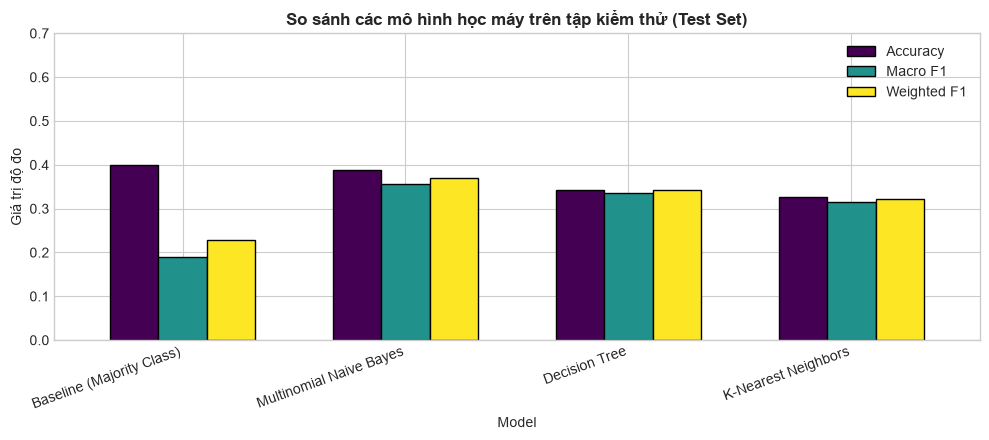

In [15]:
summary_df = pd.DataFrame([baseline_res, nb_res, dt_res, knn_res])
display(summary_df)

# Biểu đồ so sánh
fig, ax = plt.subplots(figsize=(10, 4.5))
summary_df.set_index('Model')[['Accuracy', 'Macro F1', 'Weighted F1']].plot(kind='bar', ax=ax, colormap='viridis', edgecolor='black', width=0.65)
plt.title("So sánh các mô hình học máy trên tập kiểm thử (Test Set)", fontweight='bold')
plt.ylabel("Giá trị độ đo")
plt.ylim(0, 0.7)
plt.xticks(rotation=20, ha='right')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


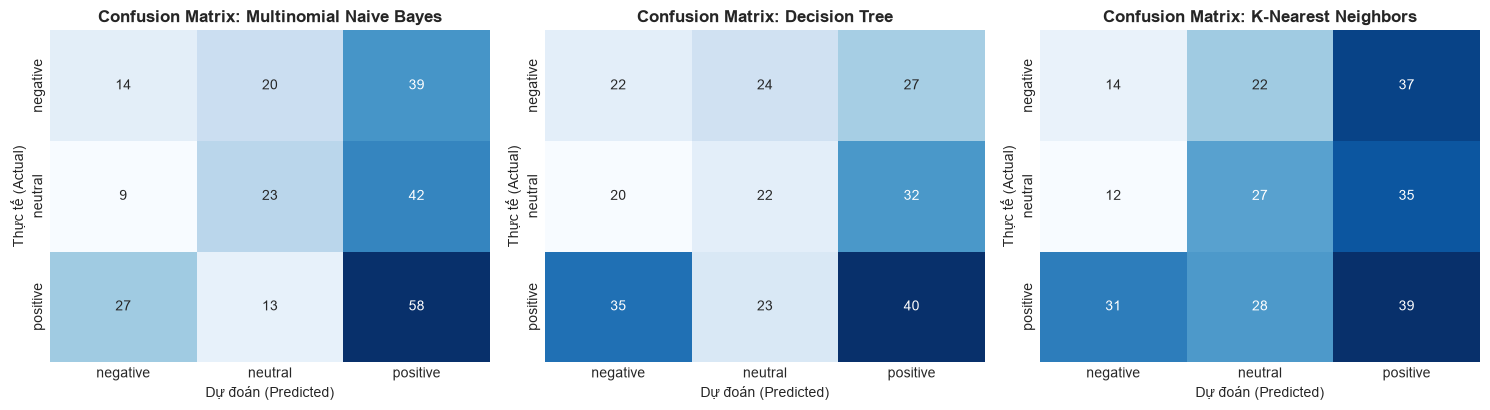

In [16]:
# Vẽ Confusion Matrix của 3 mô hình chính
classes = sorted(list(y.unique()))
models_dict = {
    "Multinomial Naive Bayes": y_pred_nb,
    "Decision Tree": y_pred_dt,
    "K-Nearest Neighbors": y_pred_knn
}

plt.figure(figsize=(15, 4.2))
for i, (m_name, m_preds) in enumerate(models_dict.items(), 1):
    plt.subplot(1, 3, i)
    cm = confusion_matrix(y_test, m_preds, labels=classes)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes, cbar=False)
    plt.title(f"Confusion Matrix: {m_name}", fontweight='bold')
    plt.xlabel("Dự đoán (Predicted)")
    plt.ylabel("Thực tế (Actual)")
plt.tight_layout()
plt.show()


### 8. Phân tích lỗi (Error Analysis)
Phân tích các mẫu dự đoán sai của mô hình tốt nhất (Multinomial Naive Bayes) để tìm hiểu nguyên nhân cốt lõi:
- Các cặp lớp hay bị nhầm lẫn nhất (ví dụ Neutral bị nhầm sang Positive/Negative)
- Tác động của cờ châm biếm (`sarcasm_flag`)
- Kiểm tra các mẫu cụ thể kèm xác suất dự đoán (`predicted probabilities`).


In [17]:
test_indices = X_test.index
test_df = df.loc[test_indices].copy()
test_df['predicted'] = y_pred_nb
test_df['is_correct'] = test_df['sentiment_label'] == test_df['predicted']

print(f"Tỷ lệ dự đoán sai: {(~test_df['is_correct']).mean():.2%}")
print("\nPhân phối nhầm lẫn giữa các nhãn (Actual -> Predicted):")
confused = test_df[~test_df['is_correct']].groupby(['sentiment_label', 'predicted']).size().reset_index(name='count')
display(confused.sort_values(by='count', ascending=False))

print("\nTỷ lệ dự đoán sai theo cờ châm biếm (Sarcasm):")
sarcasm_err = pd.crosstab(test_df['sarcasm_flag'], test_df['is_correct'], normalize='index') * 100
sarcasm_err.columns = ['Sai (%)', 'Đúng (%)']
sarcasm_err.index = ['Không châm biếm (0)', 'Châm biếm (1)']
display(sarcasm_err.round(2))


Tỷ lệ dự đoán sai: 61.22%

Phân phối nhầm lẫn giữa các nhãn (Actual -> Predicted):


,sentiment_label,predicted,count
3,neutral,positive,42
1,negative,positive,39
4,positive,negative,27
0,negative,neutral,20
5,positive,neutral,13
2,neutral,negative,9



Tỷ lệ dự đoán sai theo cờ châm biếm (Sarcasm):


,Sai (%),Đúng (%)
Không châm biếm (0),59.41,40.59
Châm biếm (1),69.77,30.23


In [18]:
# Trích xuất một số câu dự đoán sai cụ thể kèm xác suất
probs = best_nb.predict_proba(X_test_vec)
prob_df = pd.DataFrame(probs, columns=[f"prob_{c}" for c in best_nb.classes_], index=test_indices)
merged_err = pd.concat([test_df, prob_df], axis=1)

sample_errs = merged_err[~merged_err['is_correct']].head(5)
for _, r in sample_errs.iterrows():
    text_val = r['feedback_text']
    print(f"Văn bản:    '{text_val}'")
    print(f"Thực tế:    {r['sentiment_label']} (Emotion: {r['emotion_tag']}, Sarcasm: {r['sarcasm_flag']})")
    print(f"Dự đoán:    {r['predicted']}")
    print(f"Xác suất:   Negative={r['prob_negative']:.2f}, Neutral={r['prob_neutral']:.2f}, Positive={r['prob_positive']:.2f}")
    print("-" * 60)


Văn bản:    'Offer meeting daughter somebody throughout environment claim law be.'
Thực tế:    negative (Emotion: anger, Sarcasm: 0)
Dự đoán:    positive
Xác suất:   Negative=0.30, Neutral=0.25, Positive=0.45
------------------------------------------------------------
Văn bản:    'Skin memory leader full floor benefit hold room size their responsibility away example card exist imagine them indicate.'
Thực tế:    negative (Emotion: fear, Sarcasm: 0)
Dự đoán:    neutral
Xác suất:   Negative=0.37, Neutral=0.40, Positive=0.23
------------------------------------------------------------
Văn bản:    'Reveal its million teacher now agree.'
Thực tế:    neutral (Emotion: anger, Sarcasm: 1)
Dự đoán:    negative
Xác suất:   Negative=0.37, Neutral=0.30, Positive=0.33
------------------------------------------------------------
Văn bản:    'Son bring simply can image help improve have head doctor.'
Thực tế:    positive (Emotion: fear, Sarcasm: 0)
Dự đoán:    negative
Xác suất:   Negative=0.42, Neu

### 9. Kết luận và hướng phát triển
**1. Tóm tắt kết quả chính:**
- **Multinomial Naive Bayes** đạt hiệu năng cân bằng nhất giữa các lớp (Macro-F1 ~ 0.357 - 0.380) so với Baseline (0.1905). Mô hình hoạt động ổn định trên không gian đặc trưng văn bản thưa thớt (sparse text features).
- **Decision Tree** và **K-NN** gặp khó khăn trong việc phân tách các ranh giới quyết định phức tạp trong không gian từ vựng đa chiều do hiện tượng lời nguyền số chiều (Curse of Dimensionality) và tính thiếu cấu trúc phân cấp mạnh.
- **Biểu diễn đặc trưng:** Unigram TF-IDF và BoW cho kết quả vượt trội so với n-gram (1,2) vì bigram làm bùng nổ số chiều (từ 767 lên hơn 8,600 từ vựng), gây phân tán dữ liệu trầm trọng trên tập 978 mẫu huấn luyện.
- **Yếu tố châm biếm (Sarcasm):** Các câu mang cờ châm biếm có tỷ lệ dự đoán sai tăng lên ~69.77% so với ~59.41% ở các câu thông thường, minh chứng cho giới hạn của giả định độc lập từ vựng trong mô hình BoW/TF-IDF.

**2. Hướng phát triển:**
- Thu thập thêm dữ liệu phản hồi sinh viên tự nhiên trong môi trường học đường thực tế.
- Tích hợp thêm các đặc trưng siêu dữ liệu (metadata như `feedback_type`, `department`, `subject_specific_context`).
- Thử nghiệm các mô hình nhúng câu hiện đại (Sentence Transformers/BERT) để nắm bắt ngữ nghĩa và ngữ cảnh châm biếm sâu hơn khi được mở rộng ngoài các thuật toán cơ bản.
